#### The inverse travelling wave
 HSG
 20.09

In [2]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [3]:
print("heyo")

heyo


In [4]:
import numpy as np 
import matplotlib.pyplot as plt 
from nonlinear.spectralNewton import solve_with_continuation

In [5]:
# Let us create a travelling wave:
P = 2*np.pi
N = 2**8

amp_target = 0.05
mean = 0.0

u, mk, mask = solve_with_continuation(P=P, amp_target=amp_target, N=N, mean=mean)

phi_hat = u[:-2]
c_sol, B_sol = u[-2], u[-1]

x = np.linspace(0,P,N, endpoint=False)
dx = P/N
#rfft wave numbers
k = 2*np.pi*np.fft.rfftfreq(N,dx)

In [6]:
def nonlinear_hat(phi_hat,mask,N):
    phi = np.fft.irfft(phi_hat*mask,n=N)
    nl = 0.5*phi**2
    return np.fft.rfft(nl)

In [ ]:
nl_hat = nonlinear_hat(phi_hat,mask,N)
mk_lsm = np.ones_like(phi_hat, dtype=complex)
mk_lsm [1:] = c_sol - nl_hat[1:]/phi_hat[1:]

C:\Users\henri\AppData\Local\Temp\ipykernel_21808\864487514.py:3: ComplexWarning: Casting complex values to real discards the imaginary part
  mk_lsm [1:] = c_sol - nl_hat[1:]/phi_hat[1:]


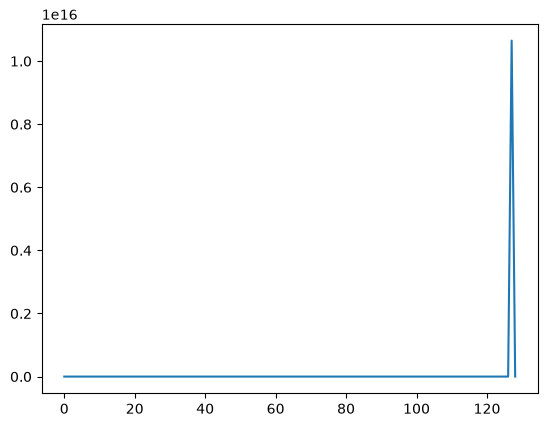

In [8]:
plt.plot(k, mk - mk_lsm.real)

In [9]:
plot_mask = np.abs(mk - mk_lsm.real) < 1e3

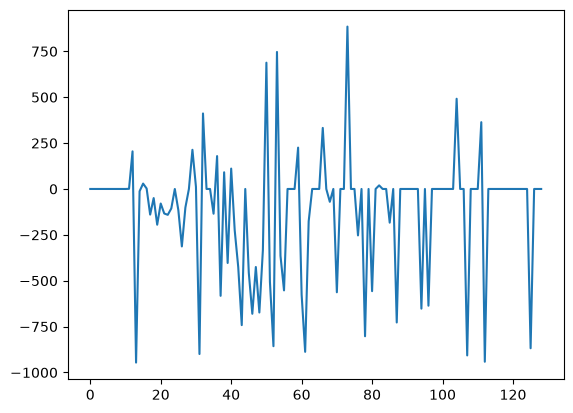

In [10]:
k_p = k*plot_mask
diff_plot = (mk - mk_lsm.real)*plot_mask
plt.plot(k, diff_plot)
plt.show()

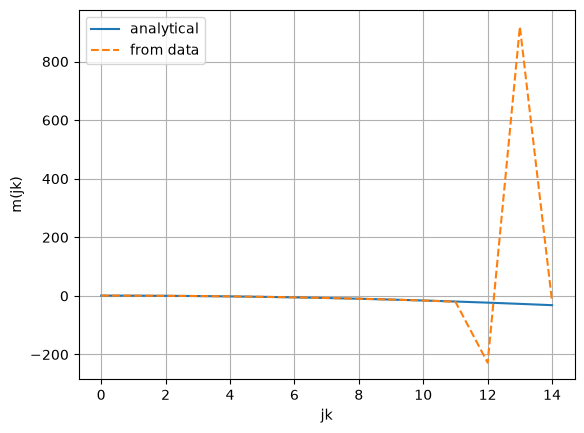

In [11]:
idx = 15
plt.plot(k[:idx], mk[:idx] , label = "analytical")
plt.plot(k[:idx], mk_lsm.real[:idx], '--' , label = "from data")
plt.xlabel("jk")
plt.ylabel("m(jk)")
plt.legend()
plt.grid()
plt.show()

Kan se ut som om det kun er gyldig for $j < 10$

In [17]:
# LSM on the "valid area" 
idx_ = 11
k_lsm = k[:idx_]
mk_lsm_ = mk_lsm[:idx_]
A = np.column_stack([np.ones_like(k_lsm), k_lsm , k_lsm**2, k_lsm**3, k_lsm**4])
x,residual, rank , s = np.linalg.lstsq(A,mk_lsm_.real, rcond=None)

print(x)

[ 9.99586174e-01  2.29893936e-03 -1.68132211e-01  2.87357645e-04
 -1.72413289e-05]
